# Projeto de Análise de Big Data

## 1. Descrição do Projeto

O projeto tem como objetivo desenvolver uma pipeline de análise de Big Data segunda a estrutura da arquitetura Medallion, utilizando Spark e Hadoop para o processamento, armazenamento e Transformação dos dados.
Numa primeira fase, será realizada a recolha de dados de um dataset obtido através de uma API aberta na internet. Os dados serão enviados e armazenados no Hadoop usando o Spark. Os dados serão guardados na camada Bronze em Raw Data.
De seguida, será efetuado o processo de limpeza e preparação dos dados. Após esta limpeza, os dados serão processados com Spark e armazenados no Hadoop na camada silver.
Na fase seguinte, serão realizadas transformações necessárias ao dataset em silver, com o objetivo de criar uma versão final dos dados adequada à análise. O resultado será enviado com Spark para Hadoop e armazenado na camada gold.
Por fim, serão desenvolvidas métricas e dashboards com base no dataset em gold.

## 2. Descrição dos conjuntos de Dados

O dataset raw foi extraído da World Bank Indicators API e contém dados anuais de vários indicadores económicos, financeiros e demográficos para países e agregados internacionais. A extração cobre o período de 2010 a 2024 e inclui indicadores como PIB, crescimento do PIB, PIB per capita, inflação, dívida pública, receita pública, despesa pública e população total.

Nesta camada raw/bronze, os dados são guardados no formato JSON original, preservando a estrutura devolvida pela API, incluindo metadados da extração, período analisado, identificação dos indicadores e respetivos registos por país e ano. Esta camada serve como base inicial do pipeline ELT, antes da limpeza, normalização de tipos, remoção de duplicados e conversão para Parquet nas camadas seguintes.

## 3. Pipeline

### 3.1. Bronze

In [ ]:
import json
from datetime import datetime
from pathlib import Path

import requests
from hdfs import InsecureClient


START_YEAR = 2010
END_YEAR = 2024
PER_PAGE = 20000

HDFS_HTTP = "http://hadoop-master:38180"
HDFS_WEB = "webhdfs://hadoop-master:38180"
HDFS_BRONZE_DIR = "/2240119/projeto/bronze"

hdfs_client = InsecureClient(HDFS_HTTP, user="hadoop")

INDICATORS = [
    {"id": "NY.GDP.MKTP.CD", "name": "GDP (current US$)", "category": "economy"},
    {"id": "NY.GDP.MKTP.KD.ZG", "name": "GDP growth (annual %)", "category": "economy"},
    {"id": "NY.GDP.PCAP.CD", "name": "GDP per capita (current US$)", "category": "economy"},
    {"id": "FP.CPI.TOTL.ZG", "name": "Inflation (annual %)", "category": "finance"},
    {"id": "GC.DOD.TOTL.GD.ZS", "name": "Central government debt (% of GDP)", "category": "public_finance"},
    {"id": "GC.REV.XGRT.GD.ZS", "name": "Government revenue (% of GDP)", "category": "public_finance"},
    {"id": "NE.CON.GOVT.ZS", "name": "Government expenditure (% of GDP)", "category": "public_finance"},
    {"id": "SP.POP.TOTL", "name": "Population total", "category": "demographics"},
]


def get_indicator_records(indicator_id):
    url = f"https://api.worldbank.org/v2/country/all/indicator/{indicator_id}"

    response = requests.get(
        url,
        params={
            "format": "json",
            "date": f"{START_YEAR}:{END_YEAR}",
            "per_page": PER_PAGE,
        },
        timeout=60,
    )

    response.raise_for_status()
    data = response.json()

    return data[1] if isinstance(data, list) and len(data) > 1 and data[1] else []


extract_timestamp = datetime.now()
extract_id = extract_timestamp.strftime("%Y-%m-%d_%H-%M-%S")

dataset = {
    "source": "World Bank Indicators API",
    "extract_timestamp": extract_timestamp.isoformat(),
    "period": {
        "start_year": START_YEAR,
        "end_year": END_YEAR,
    },
    "data": [],
}

for indicator in INDICATORS:
    print(f"A extrair {indicator['id']}...")
    records = get_indicator_records(indicator["id"])

    dataset["data"].append({
        "indicator": indicator,
        "records_count": len(records),
        "records": records,
    })

local_json_path = Path(f"worldbank_all_data_{extract_id}.json")

with open(local_json_path, "w", encoding="utf-8") as f:
    json.dump(dataset, f, ensure_ascii=False, indent=2)

print(f"JSON criado localmente: {local_json_path}")

json_filename = f"worldbank_all_data_{extract_id}.json"
hdfs_json_path = f"{HDFS_BRONZE_DIR}/{json_filename}"

with hdfs_client.write(
    hdfs_json_path,
    encoding="utf-8",
    overwrite=False
) as writer:
    json.dump(dataset, writer, ensure_ascii=False, indent=2)

bronze_json_path = f"{HDFS_WEB}{HDFS_BRONZE_DIR}/{local_json_path.name}"

print(f"Bronze criada: {bronze_json_path}")

### 3.2. Limpeza de bronze para Silver

Na passagem da camada Bronze para a camada Silver, os dados raw em JSON são transformados numa estrutura tabular mais adequada para análise. Nesta etapa, os registos aninhados da API são expandidos, separando os indicadores, países, anos e valores em colunas próprias.

Também são aplicadas operações de limpeza, como a conversão dos tipos de dados, transformação de valores vazios em null, criação da coluna extract_date e remoção de duplicados com base no indicador, país, ano e timestamp da extração. Por fim, o dataset limpo é guardado em formato Parquet, tornando-o mais eficiente para processamento em Spark e posterior análise.

In [4]:
from pathlib import Path

from hdfs import InsecureClient
from pyspark.sql import SparkSession
from pyspark.sql import functions as F


spark = SparkSession.builder.appName("WorldBank Silver").getOrCreate()

HDFS_HTTP = "http://hadoop-master:38180"
HDFS_WEB = "webhdfs://hadoop-master:38180"

HDFS_SILVER_DIR = "/2240119/projeto/silver"

hdfs_client = InsecureClient(HDFS_HTTP, user="hadoop")

raw_df = spark.read \
    .option("multiLine", "true") \
    .json(bronze_json_path)

silver_df = raw_df \
    .withColumn("indicator_block", F.explode_outer("data")) \
    .withColumn("record", F.explode_outer("indicator_block.records")) \
    .select(
        F.col("source"),
        F.to_timestamp("extract_timestamp").alias("extract_timestamp"),
        F.col("period.start_year").cast("int").alias("start_year"),
        F.col("period.end_year").cast("int").alias("end_year"),

        F.col("indicator_block.indicator.id").alias("indicator_id"),
        F.col("indicator_block.indicator.name").alias("indicator_name"),
        F.col("indicator_block.indicator.category").alias("category"),
        F.col("indicator_block.records_count").cast("int").alias("records_count"),

        F.col("record.country.id").alias("country_id"),
        F.col("record.country.value").alias("country_name"),
        F.col("record.countryiso3code").alias("countryiso3code"),
        F.col("record.date").cast("int").alias("year"),
        F.col("record.value").cast("double").alias("value"),
        F.col("record.unit").alias("unit"),
        F.col("record.obs_status").alias("obs_status"),
        F.col("record.decimal").cast("int").alias("decimal")
    ) \
    .withColumn("country_id", F.when(F.trim(F.col("country_id")) == "", None).otherwise(F.col("country_id"))) \
    .withColumn("country_name", F.when(F.trim(F.col("country_name")) == "", None).otherwise(F.col("country_name"))) \
    .withColumn("countryiso3code", F.when(F.trim(F.col("countryiso3code")) == "", None).otherwise(F.col("countryiso3code"))) \
    .withColumn("unit", F.when(F.trim(F.col("unit")) == "", None).otherwise(F.col("unit"))) \
    .withColumn("obs_status", F.when(F.trim(F.col("obs_status")) == "", None).otherwise(F.col("obs_status"))) \
    .withColumn("extract_date", F.to_date("extract_timestamp")) \
    .dropDuplicates(["indicator_id", "country_id", "year", "extract_timestamp"])

local_silver_path = Path(f"silver_worldbank_{extract_id}")

silver_df.write \
    .mode("overwrite") \
    .parquet(str(local_silver_path))

hdfs_client.upload(
    HDFS_SILVER_DIR,
    str(local_silver_path),
    overwrite=False
)

silver_path = f"{HDFS_WEB}{HDFS_SILVER_DIR}/{local_silver_path.name}"

print(f"Silver criada: {silver_path}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/05/26 16:35:12 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/05/26 16:35:13 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/05/26 16:35:13 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.
26/05/26 16:35:13 WARN Utils: Service 'SparkUI' could not bind on port 4042. Attempting port 4043.
26/05/26 16:35:13 WARN Utils: Service 'SparkUI' could not bind on port 4043. Attempting port 4044.
26/05/26 16:35:13 WARN Utils: Service 'SparkUI' could not bind on port 4044. Attempting port 4045.
26/05/26 16:35:13 WARN Utils: Service 'SparkUI' could not bind on port 4045. Attempting port 4046.
26/05/26 16:35:13 WARN Utils: Service 'SparkUI' could not bind on port 4046. Attempting port 4047.
26/05/26 16:35:13 WARN Utils: Serv

Silver criada: webhdfs://hadoop-master:38180/2240119/projeto/silver/silver_worldbank_2026-05-26_16-34-53


### 3.3 Limpeza de silver para gold

Na passagem da camada Silver para a camada Gold, os dados já limpos são enriquecidos para ficarem mais adequados à análise e criação de dashboards. Nesta etapa são criadas colunas auxiliares, como entity_code, que identifica cada entidade, has_value, que indica se existe valor disponível, decade, que agrupa os anos por década, e entity_type, que classifica as entidades como país, região agregada, grupo de rendimento ou entidade desconhecida.

A camada Gold representa a versão mais preparada para consumo analítico, permitindo fazer queries em Spark SQL e construir dashboards de forma mais simples e eficiente.

In [5]:
from pathlib import Path

from hdfs import InsecureClient
from pyspark.sql import functions as F


HDFS_HTTP = "http://hadoop-master:38180"
HDFS_WEB = "webhdfs://hadoop-master:38180"

HDFS_GOLD_DIR = "/2240119/projeto/gold"

hdfs_client = InsecureClient(HDFS_HTTP, user="hadoop")

AGGREGATE_ISO3_CODES = [
    "AFE", "AFW", "ARB", "CEB", "CSS", "EAP", "EAR", "EAS", "ECA", "ECS",
    "EMU", "EUU", "FCS", "HIC", "HPC", "IBD", "IBT", "IDA", "IDB", "IDX",
    "LAC", "LCN", "LDC", "LIC", "LMC", "LMY", "LTE", "MEA", "MIC", "MNA",
    "NAC", "OED", "OSS", "PRE", "PST", "SAS", "SSA", "SSF", "SST", "TEA",
    "TEC", "TLA", "TMN", "TSA", "TSS", "UMC", "WLD"
]

INCOME_GROUP_IDS = ["XD", "XM", "XN", "XT", "XY"]

gold_df = silver_df \
    .withColumn("entity_code", F.coalesce(F.col("countryiso3code"), F.col("country_id"))) \
    .withColumn("has_value", F.col("value").isNotNull()) \
    .withColumn("decade", (F.floor(F.col("year") / 10) * 10).cast("int")) \
    .withColumn(
        "entity_type",
        F.when(F.col("country_id").isin(INCOME_GROUP_IDS), "income_group_or_unclassified")
         .when(F.col("countryiso3code").isin(AGGREGATE_ISO3_CODES), "aggregate_region")
         .when(F.col("countryiso3code").isNull(), "unknown_or_aggregate")
         .otherwise("country")
    )

local_gold_path = Path(f"gold_worldbank_{extract_id}")

gold_df.write \
    .mode("overwrite") \
    .parquet(str(local_gold_path))

hdfs_client.upload(
    HDFS_GOLD_DIR,
    str(local_gold_path),
    overwrite=False
)

gold_path = f"{HDFS_WEB}{HDFS_GOLD_DIR}/{local_gold_path.name}"

print(f"Gold criada: {gold_path}")
spark.stop()

Gold criada: webhdfs://hadoop-master:38180/2240119/projeto/gold/gold_worldbank_2026-05-26_16-34-53


## 4. Análises Métricas em Spark

In [6]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

In [7]:
spark = SparkSession.builder.appName("WorldBank Dashboards").getOrCreate()

26/05/26 16:35:29 WARN Utils: Service 'SparkUI' could not bind on port 4040. Attempting port 4041.
26/05/26 16:35:29 WARN Utils: Service 'SparkUI' could not bind on port 4041. Attempting port 4042.
26/05/26 16:35:29 WARN Utils: Service 'SparkUI' could not bind on port 4042. Attempting port 4043.
26/05/26 16:35:29 WARN Utils: Service 'SparkUI' could not bind on port 4043. Attempting port 4044.
26/05/26 16:35:29 WARN Utils: Service 'SparkUI' could not bind on port 4044. Attempting port 4045.
26/05/26 16:35:29 WARN Utils: Service 'SparkUI' could not bind on port 4045. Attempting port 4046.
26/05/26 16:35:29 WARN Utils: Service 'SparkUI' could not bind on port 4046. Attempting port 4047.
26/05/26 16:35:29 WARN Utils: Service 'SparkUI' could not bind on port 4047. Attempting port 4048.
26/05/26 16:35:29 WARN Utils: Service 'SparkUI' could not bind on port 4048. Attempting port 4049.


In [8]:
gold_df = spark.read.parquet("webhdfs://hadoop-master:38180/2240119/projeto/gold/gold_worldbank_*")

In [9]:
gold_df.createOrReplaceTempView("worldbank_gold")

In [10]:
gold_df.printSchema()

root
 |-- source: string (nullable = true)
 |-- extract_timestamp: timestamp (nullable = true)
 |-- start_year: integer (nullable = true)
 |-- end_year: integer (nullable = true)
 |-- indicator_id: string (nullable = true)
 |-- indicator_name: string (nullable = true)
 |-- category: string (nullable = true)
 |-- records_count: integer (nullable = true)
 |-- country_id: string (nullable = true)
 |-- country_name: string (nullable = true)
 |-- countryiso3code: string (nullable = true)
 |-- year: integer (nullable = true)
 |-- value: double (nullable = true)
 |-- unit: string (nullable = true)
 |-- obs_status: string (nullable = true)
 |-- decimal: integer (nullable = true)
 |-- extract_date: date (nullable = true)
 |-- entity_code: string (nullable = true)
 |-- has_value: boolean (nullable = true)
 |-- decade: integer (nullable = true)
 |-- entity_type: string (nullable = true)



In [11]:
gold_df.show(5)

+--------------------+--------------------+----------+--------+--------------+--------------------+--------+-------------+----------+------------+---------------+----+-----+----+----------+-------+------------+-----------+---------+------+----------------+
|              source|   extract_timestamp|start_year|end_year|  indicator_id|      indicator_name|category|records_count|country_id|country_name|countryiso3code|year|value|unit|obs_status|decimal|extract_date|entity_code|has_value|decade|     entity_type|
+--------------------+--------------------+----------+--------+--------------+--------------------+--------+-------------+----------+------------+---------------+----+-----+----+----------+-------+------------+-----------+---------+------+----------------+
|World Bank Indica...|2026-05-25 17:11:...|      2010|    2024|FP.CPI.TOTL.ZG|Inflation (annual %)| finance|         3990|        1A|  Arab World|            ARB|2010| NULL|NULL|      NULL|      1|  2026-05-25|        ARB|    fal

In [10]:
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

#### Queries SQL

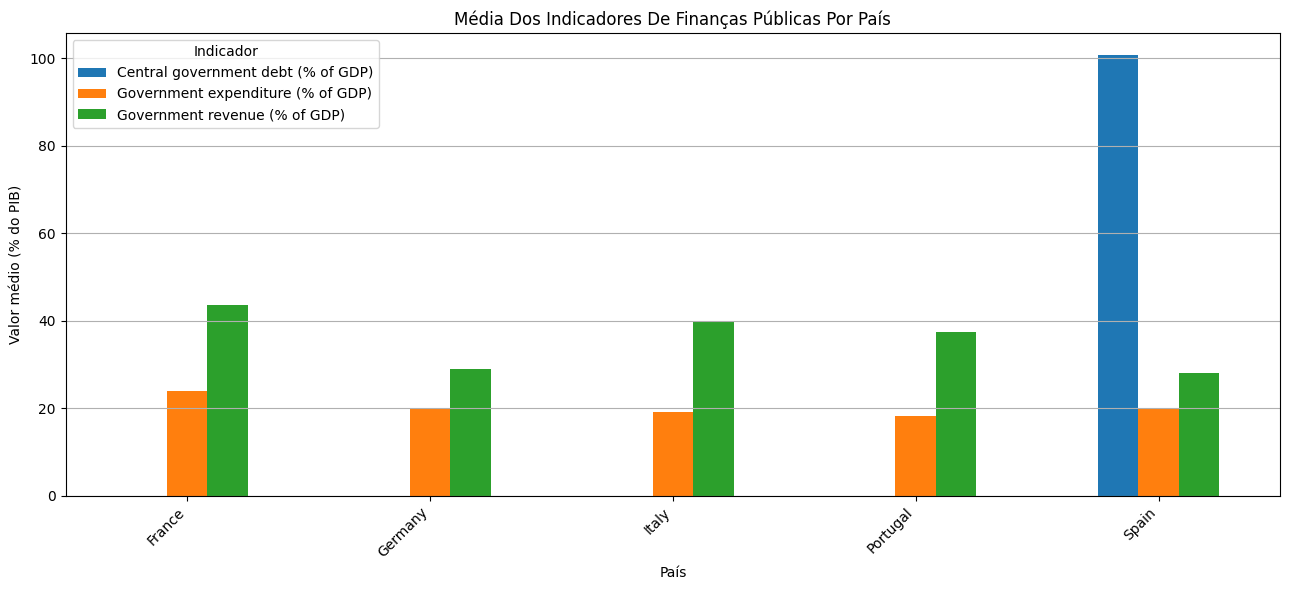

In [16]:
countries = ["Portugal", "Spain", "France", "Germany", "Italy"]

compare_pf = spark.sql(f"""
    SELECT
        country_name,
        indicator_name,
        ROUND(AVG(value), 2) AS avg_value
    FROM worldbank_gold
    WHERE country_name IN ({",".join([f"'{c}'" for c in countries])})
      AND indicator_id IN (
          'GC.DOD.TOTL.GD.ZS',
          'GC.REV.XGRT.GD.ZS',
          'NE.CON.GOVT.ZS'
      )
      AND value IS NOT NULL
    GROUP BY country_name, indicator_name
    ORDER BY country_name, indicator_name
""").toPandas()

pivot_pf = compare_pf.pivot(
    index="country_name",
    columns="indicator_name",
    values="avg_value"
)

pivot_pf.plot(kind="bar", figsize=(13, 6))

plt.title("Média Dos Indicadores De Finanças Públicas Por País")
plt.xlabel("País")
plt.ylabel("Valor médio (% do PIB)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Indicador")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

In [19]:
debt_revenue_ratio = spark.sql("""
    WITH base AS (
        SELECT
            country_name,
            countryiso3code,
            year,
            MAX(CASE WHEN indicator_id = 'GC.DOD.TOTL.GD.ZS' THEN value END) AS debt_pct_gdp,
            MAX(CASE WHEN indicator_id = 'GC.REV.XGRT.GD.ZS' THEN value END) AS revenue_pct_gdp
        FROM worldbank_gold
        WHERE entity_type = 'country'
          AND indicator_id IN ('GC.DOD.TOTL.GD.ZS', 'GC.REV.XGRT.GD.ZS')
          AND year >= 2020
        GROUP BY country_name, countryiso3code, year
    ),
    ranked AS (
        SELECT
            *,
            debt_pct_gdp / revenue_pct_gdp AS debt_revenue_ratio,
            ROW_NUMBER() OVER (
                PARTITION BY country_name
                ORDER BY year DESC
            ) AS rn
        FROM base
        WHERE debt_pct_gdp IS NOT NULL
          AND revenue_pct_gdp IS NOT NULL
          AND revenue_pct_gdp > 0
    )
    SELECT
        country_name,
        countryiso3code,
        year,
        debt_pct_gdp,
        revenue_pct_gdp,
        debt_revenue_ratio
    FROM ranked
    WHERE rn = 1
    ORDER BY debt_revenue_ratio DESC
""").toPandas()

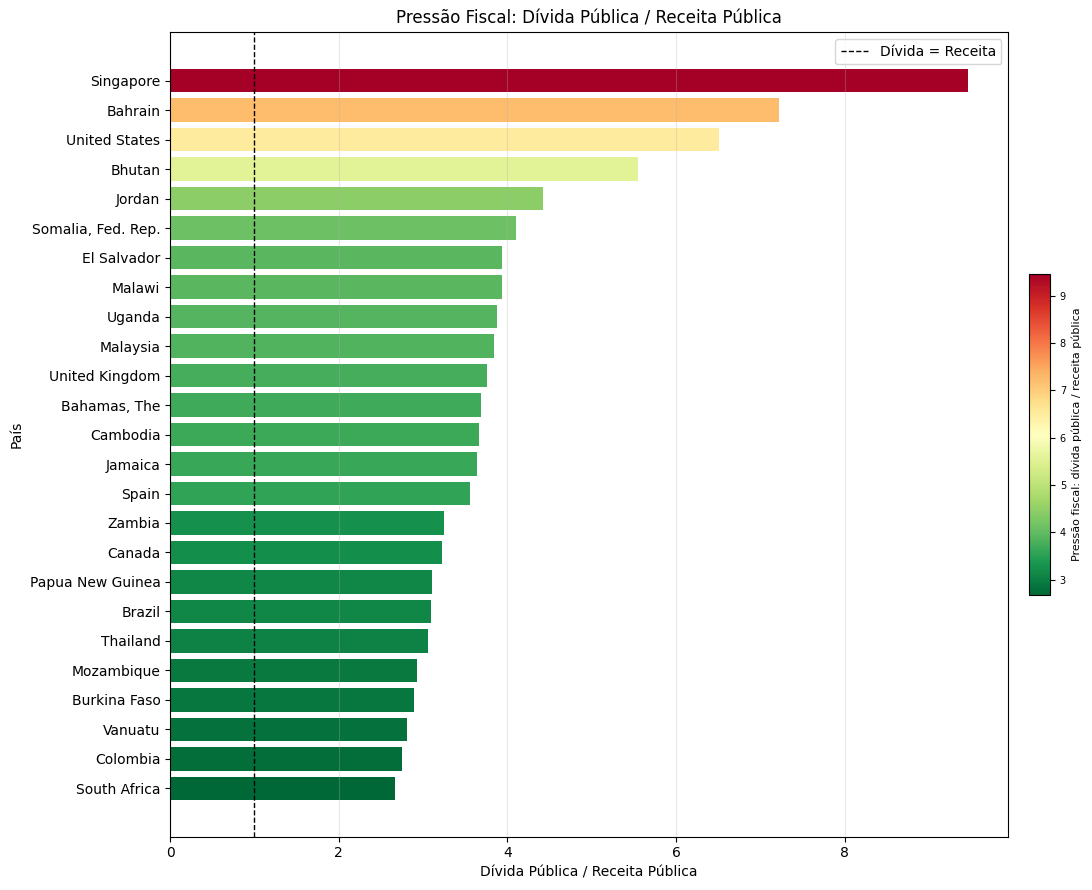

In [26]:
top_ratio = debt_revenue_ratio.head(25).sort_values("debt_revenue_ratio")

plt.figure(figsize=(12, 9))

norm = matplotlib.colors.Normalize(
    vmin=top_ratio["debt_revenue_ratio"].min(),
    vmax=top_ratio["debt_revenue_ratio"].max()
)

cmap = plt.cm.RdYlGn_r

colors = cmap(norm(top_ratio["debt_revenue_ratio"]))

bars = plt.barh(
    top_ratio["country_name"],
    top_ratio["debt_revenue_ratio"],
    color=colors
)

plt.axvline(1, color="black", linestyle="--", linewidth=1, label="Dívida = Receita")

sm = matplotlib.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

cbar = plt.colorbar(sm, ax=plt.gca(), shrink=0.4, aspect=15, pad=0.02)
cbar.set_label("Dívida / Receita", fontsize=8)
cbar.ax.tick_params(labelsize=7)
cbar.set_label("Pressão fiscal: dívida pública / receita pública")

plt.title("Pressão Fiscal: Dívida Pública / Receita Pública")
plt.xlabel("Dívida Pública / Receita Pública")
plt.ylabel("País")
plt.legend()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


Este gráfico mostra quantas vezes a dívida pública representa a receita pública anual. A linha vertical em 1 é a fronteira onde dívida e receita têm o mesmo peso. Países muito à direita têm maior pressão fiscal, porque a dívida é várias vezes superior à receita pública.

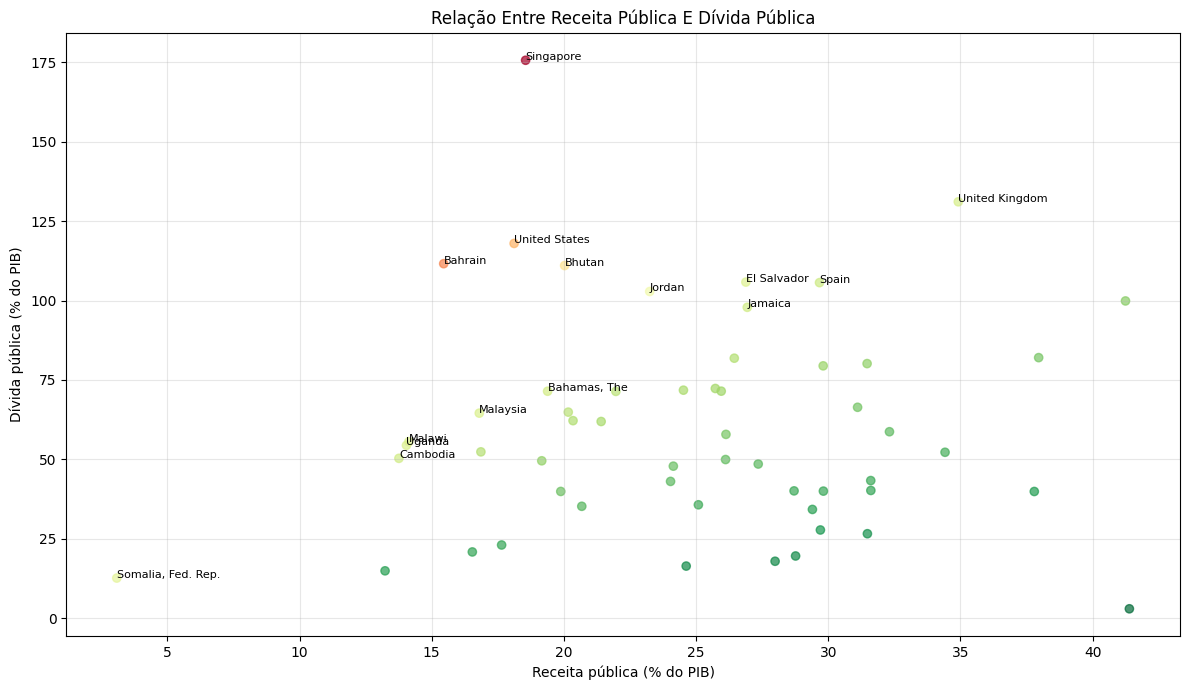

In [21]:
plot_df = debt_revenue_ratio.copy()

plt.figure(figsize=(12, 7))

colors = plt.cm.RdYlGn_r(
    plot_df["debt_revenue_ratio"] / plot_df["debt_revenue_ratio"].max()
)

plt.scatter(
    plot_df["revenue_pct_gdp"],
    plot_df["debt_pct_gdp"],
    c=colors,
    alpha=0.7
)

for _, row in plot_df.head(15).iterrows():
    plt.text(
        row["revenue_pct_gdp"],
        row["debt_pct_gdp"],
        row["country_name"],
        fontsize=8
    )

plt.title("Relação Entre Receita Pública E Dívida Pública")
plt.xlabel("Receita pública (% do PIB)")
plt.ylabel("Dívida pública (% do PIB)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Aqui vês a relação entre receita e dívida. Os países mais acima têm maior dívida pública. Os países mais à direita têm maior receita pública. A cor representa a intensidade do rácio dívida/receita: quanto mais vermelho, maior a pressão.

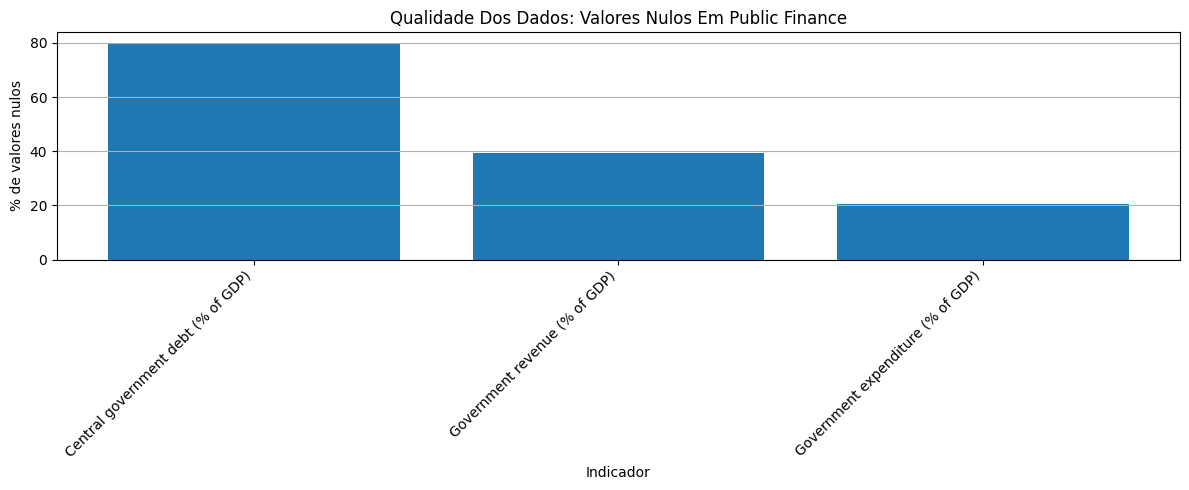

In [18]:
quality_pf = spark.sql("""
    SELECT
        indicator_name,
        COUNT(*) AS total_records,
        SUM(CASE WHEN value IS NULL THEN 1 ELSE 0 END) AS null_records,
        ROUND(SUM(CASE WHEN value IS NULL THEN 1 ELSE 0 END) / COUNT(*) * 100, 2) AS null_percentage
    FROM worldbank_gold
    WHERE category = 'public_finance'
    GROUP BY indicator_name
    ORDER BY null_percentage DESC
""").toPandas()

plt.figure(figsize=(12, 5))

plt.bar(
    quality_pf["indicator_name"],
    quality_pf["null_percentage"]
)

plt.title("Qualidade Dos Dados: Valores Nulos Em Public Finance")
plt.xlabel("Indicador")
plt.ylabel("% de valores nulos")
plt.xticks(rotation=45, ha="right")
plt.grid(axis="y")
plt.tight_layout()
plt.show()

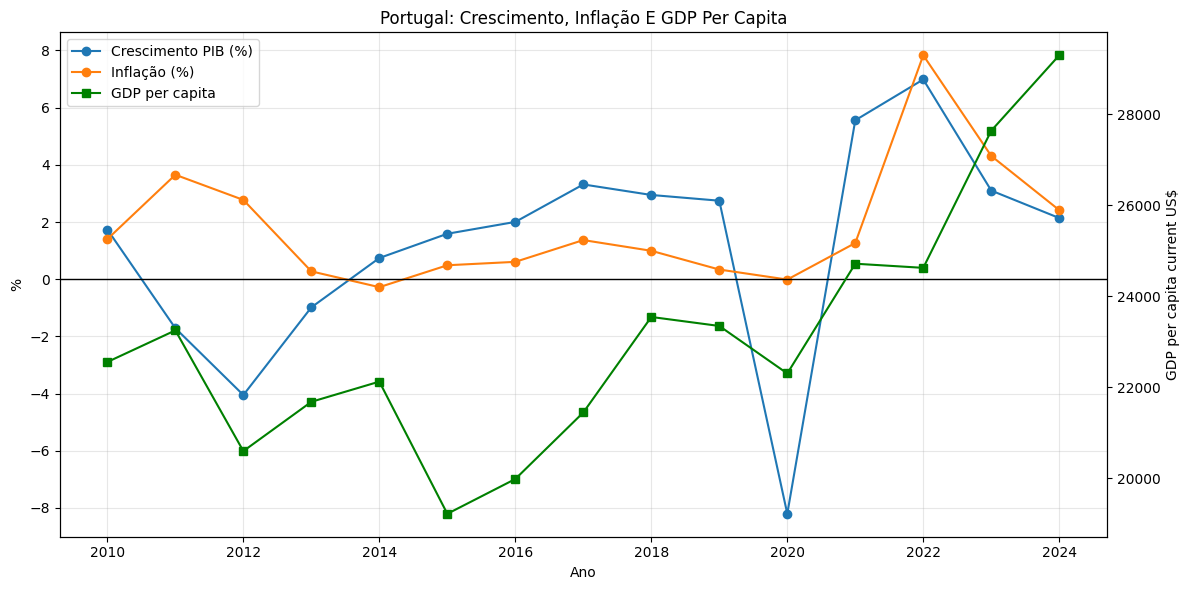

In [27]:
pt_macro = spark.sql("""
    SELECT
        year,
        MAX(CASE WHEN indicator_id = 'NY.GDP.MKTP.KD.ZG' THEN value END) AS gdp_growth,
        MAX(CASE WHEN indicator_id = 'FP.CPI.TOTL.ZG' THEN value END) AS inflation,
        MAX(CASE WHEN indicator_id = 'NY.GDP.PCAP.CD' THEN value END) AS gdp_per_capita
    FROM worldbank_gold
    WHERE LOWER(TRIM(country_name)) = 'portugal'
      AND indicator_id IN (
          'NY.GDP.MKTP.KD.ZG',
          'FP.CPI.TOTL.ZG',
          'NY.GDP.PCAP.CD'
      )
    GROUP BY year
    ORDER BY year
""").toPandas()

fig, ax1 = plt.subplots(figsize=(12, 6))

ax1.plot(pt_macro["year"], pt_macro["gdp_growth"], marker="o", label="Crescimento PIB (%)")
ax1.plot(pt_macro["year"], pt_macro["inflation"], marker="o", label="Inflação (%)")
ax1.axhline(0, color="black", linewidth=1)
ax1.set_xlabel("Ano")
ax1.set_ylabel("%")
ax1.grid(True, alpha=0.3)

ax2 = ax1.twinx()
ax2.plot(pt_macro["year"], pt_macro["gdp_per_capita"], marker="s", color="green", label="GDP per capita")
ax2.set_ylabel("GDP per capita current US$")

lines_1, labels_1 = ax1.get_legend_handles_labels()
lines_2, labels_2 = ax2.get_legend_handles_labels()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="upper left")

plt.title("Portugal: Crescimento, Inflação E GDP Per Capita")
plt.tight_layout()
plt.show()

Aqui vês a relação entre receita e dívida. Os países mais acima têm maior dívida pública. Os países mais à direita têm maior receita pública. A cor representa a intensidade do rácio dívida/receita: quanto mais vermelho, maior a pressão.

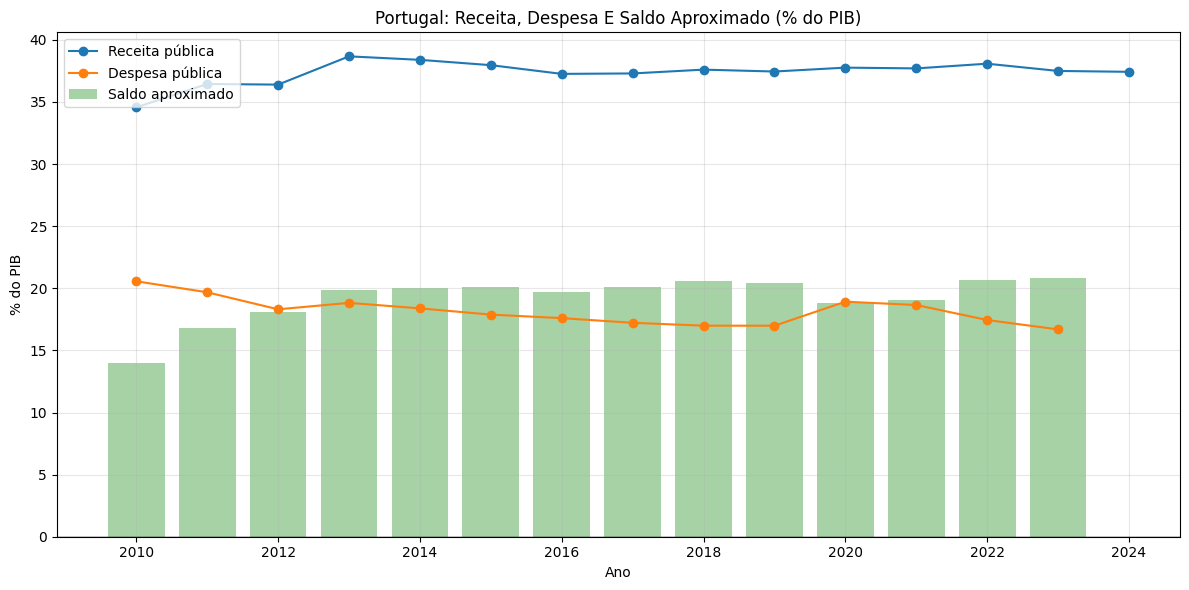

In [28]:
pt_fiscal = spark.sql("""
    SELECT
        year,
        MAX(CASE WHEN indicator_id = 'GC.REV.XGRT.GD.ZS' THEN value END) AS revenue,
        MAX(CASE WHEN indicator_id = 'NE.CON.GOVT.ZS' THEN value END) AS expenditure
    FROM worldbank_gold
    WHERE LOWER(TRIM(country_name)) = 'portugal'
      AND indicator_id IN ('GC.REV.XGRT.GD.ZS', 'NE.CON.GOVT.ZS')
    GROUP BY year
    ORDER BY year
""").toPandas()

pt_fiscal["balance_proxy"] = pt_fiscal["revenue"] - pt_fiscal["expenditure"]

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(pt_fiscal["year"], pt_fiscal["revenue"], marker="o", label="Receita pública")
ax.plot(pt_fiscal["year"], pt_fiscal["expenditure"], marker="o", label="Despesa pública")

colors = ["green" if x >= 0 else "red" for x in pt_fiscal["balance_proxy"]]
ax.bar(pt_fiscal["year"], pt_fiscal["balance_proxy"], alpha=0.35, color=colors, label="Saldo aproximado")

ax.axhline(0, color="black", linewidth=1)
ax.set_title("Portugal: Receita, Despesa E Saldo Aproximado (% do PIB)")
ax.set_xlabel("Ano")
ax.set_ylabel("% do PIB")
ax.legend()
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Aqui consegues ver se Portugal está mais próximo de equilíbrio orçamental. Barras negativas indicam despesa superior à receita; barras positivas indicam receita superior à despesa. É uma aproximação, não o saldo oficial.

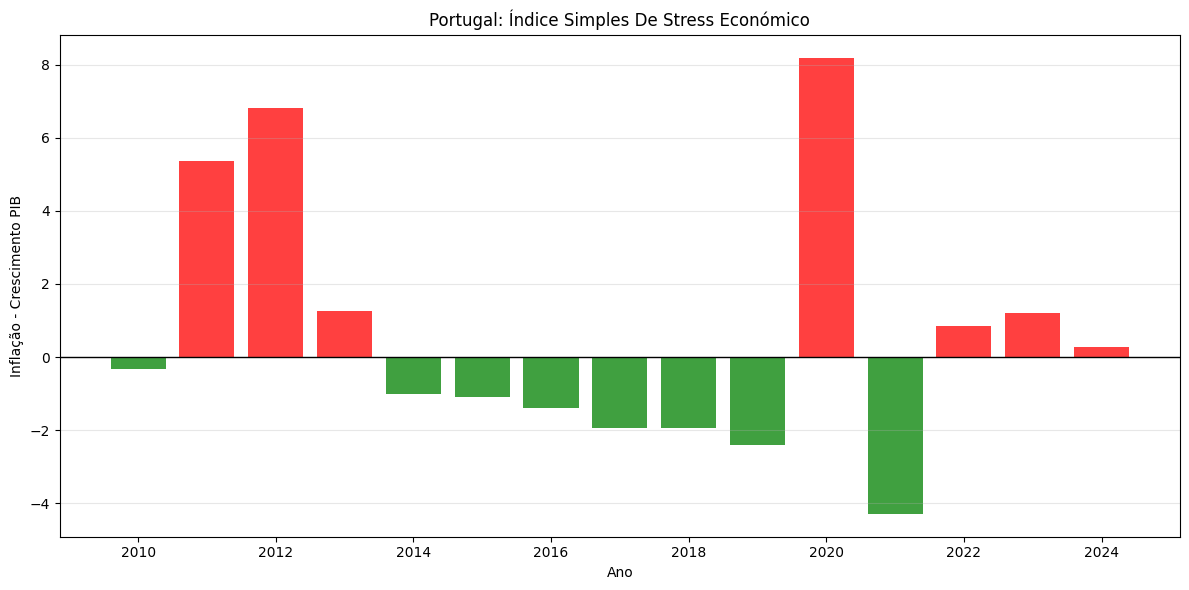

In [30]:
pt_stress = spark.sql("""
    SELECT
        year,
        MAX(CASE WHEN indicator_id = 'NY.GDP.MKTP.KD.ZG' THEN value END) AS gdp_growth,
        MAX(CASE WHEN indicator_id = 'FP.CPI.TOTL.ZG' THEN value END) AS inflation
    FROM worldbank_gold
    WHERE LOWER(TRIM(country_name)) = 'portugal'
      AND indicator_id IN ('NY.GDP.MKTP.KD.ZG', 'FP.CPI.TOTL.ZG')
    GROUP BY year
    ORDER BY year
""").toPandas()

pt_stress["stress_index"] = pt_stress["inflation"] - pt_stress["gdp_growth"]

plt.figure(figsize=(12, 6))

colors = ["red" if x > 0 else "green" for x in pt_stress["stress_index"]]

plt.bar(pt_stress["year"], pt_stress["stress_index"], color=colors, alpha=0.75)

plt.axhline(0, color="black", linewidth=1)
plt.title("Portugal: Índice Simples De Stress Económico")
plt.xlabel("Ano")
plt.ylabel("Inflação - Crescimento PIB")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

Quando o índice é positivo, a inflação está acima do crescimento económico, sugerindo maior pressão sobre famílias e empresas. Quando é negativo, o crescimento supera a inflação, um cenário geralmente mais favorável.

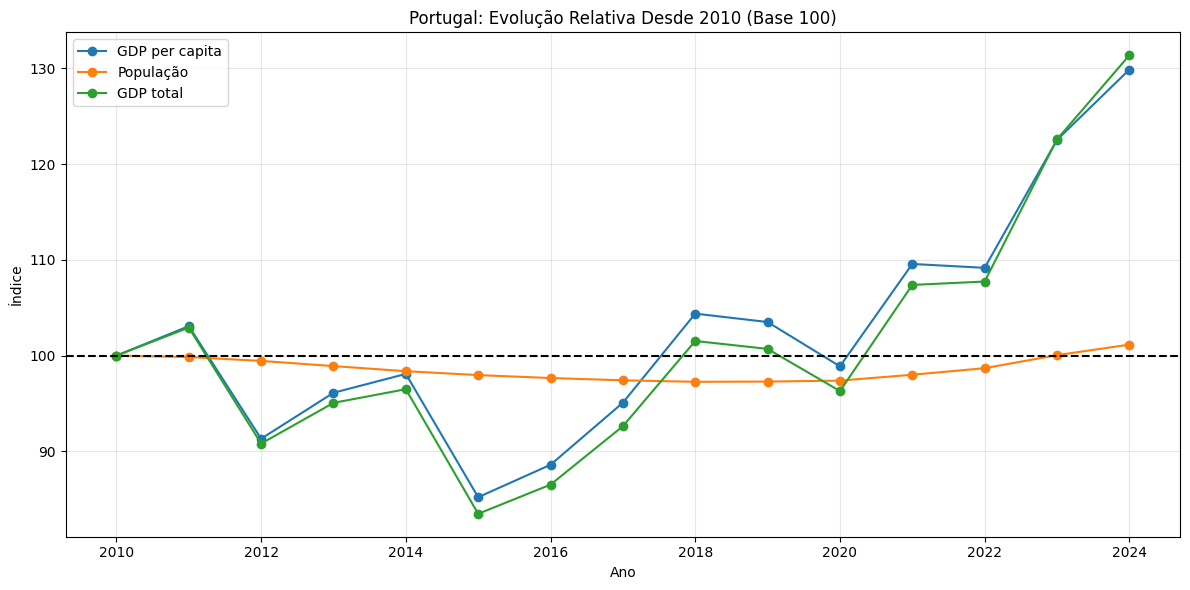

In [31]:
pt_base = spark.sql("""
    SELECT
        year,
        MAX(CASE WHEN indicator_id = 'NY.GDP.PCAP.CD' THEN value END) AS gdp_per_capita,
        MAX(CASE WHEN indicator_id = 'SP.POP.TOTL' THEN value END) AS population,
        MAX(CASE WHEN indicator_id = 'NY.GDP.MKTP.CD' THEN value END) AS gdp_total
    FROM worldbank_gold
    WHERE LOWER(TRIM(country_name)) = 'portugal'
      AND indicator_id IN ('NY.GDP.PCAP.CD', 'SP.POP.TOTL', 'NY.GDP.MKTP.CD')
    GROUP BY year
    ORDER BY year
""").toPandas()

base_year = pt_base["year"].min()
base_row = pt_base[pt_base["year"] == base_year].iloc[0]

pt_base["gdp_per_capita_index"] = pt_base["gdp_per_capita"] / base_row["gdp_per_capita"] * 100
pt_base["population_index"] = pt_base["population"] / base_row["population"] * 100
pt_base["gdp_total_index"] = pt_base["gdp_total"] / base_row["gdp_total"] * 100

plt.figure(figsize=(12, 6))

plt.plot(pt_base["year"], pt_base["gdp_per_capita_index"], marker="o", label="GDP per capita")
plt.plot(pt_base["year"], pt_base["population_index"], marker="o", label="População")
plt.plot(pt_base["year"], pt_base["gdp_total_index"], marker="o", label="GDP total")

plt.axhline(100, color="black", linestyle="--")
plt.title(f"Portugal: Evolução Relativa Desde {base_year} (Base 100)")
plt.xlabel("Ano")
plt.ylabel("Índice")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Este gráfico é bom porque coloca variáveis muito diferentes na mesma escala. Permite ver se o PIB total cresceu mais por aumento populacional ou por aumento do rendimento per capita. Também ajuda a visualizar recuperação ou estagnação desde 2010.

In [32]:
spark.stop()